# Top-20 fragment window analysis

Load the raw 15–40-residue window predictions, report the highest-sigma window for each fragment, and visualize each fragment's sigma-score distribution.

In [1]:
from pathlib import Path
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
plt.rcParams["pdf.fonttype"] = 42

WINDOW_MIN_LENGTH = 15
WINDOW_MAX_LENGTH = 40


def repo_root_from_here() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "window_sequence_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def latest_raw_predictions(results_dir: Path) -> Path:
    candidates = list((results_dir / "runs").glob("*/raw_window_predictions.csv"))
    if not candidates:
        raise FileNotFoundError(f"No raw window predictions found under {results_dir}")
    return max(candidates, key=lambda path: path.stat().st_mtime_ns)


def parse_fragment_position(position: str) -> tuple[int, int]:
    match = re.fullmatch(r"\s*(\d+)\s*[–-]\s*(\d+)\s*", str(position))
    if not match:
        raise ValueError(f"Unrecognized fragment position: {position!r}")
    return int(match.group(1)), int(match.group(2))


def fragment_coordinate_lookup(fragments: pd.DataFrame) -> dict[str, dict]:
    lookup: dict[str, dict] = {}
    for fragment_id, group in fragments.groupby("id", sort=False):
        by_type = {
            str(row.sequence_type): row
            for row in group.itertuples(index=False)
        }
        existing = by_type["existing_sequence"]
        existing_sequence = str(existing.sequence)
        frag_start, _ = parse_fragment_position(existing.position)
        before_sequence = (
            str(by_type["before_sequence"].sequence)
            if "before_sequence" in by_type
            else None
        )
        after_sequence = (
            str(by_type["after_sequence"].sequence)
            if "after_sequence" in by_type
            else None
        )
        n_flank = before_sequence.find(existing_sequence) if before_sequence else 0
        if before_sequence is not None and n_flank < 0:
            raise ValueError(f"Could not locate existing sequence in before_sequence for {fragment_id}")
        lookup[str(fragment_id)] = {
            "frag_start": frag_start,
            "n_flank": n_flank,
            "before_sequence": before_sequence,
            "existing_sequence": existing_sequence,
            "after_sequence": after_sequence,
        }
    return lookup


def original_window_position(
    lookup: dict[str, dict],
    fragment_id: str,
    sequence_type: str,
    window_start_0based: int,
    window_end_0based_exclusive: int,
) -> str:
    meta = lookup[str(fragment_id)]
    if sequence_type == "before_sequence":
        absolute_start_1based = meta["frag_start"] - meta["n_flank"]
    elif sequence_type in {"existing_sequence", "after_sequence"}:
        absolute_start_1based = meta["frag_start"]
    else:
        raise ValueError(f"Unrecognized sequence_type: {sequence_type!r}")
    residue_start = absolute_start_1based + int(window_start_0based)
    residue_end = absolute_start_1based + int(window_end_0based_exclusive) - 1
    length = residue_end - residue_start + 1
    return f"{length} ({residue_start}–{residue_end})"


def top_window_original_positions(
    top_windows: pd.DataFrame,
    fragments: pd.DataFrame,
) -> pd.DataFrame:
    lookup = fragment_coordinate_lookup(fragments)
    rows = []
    for row in top_windows.itertuples(index=False):
        rows.append(
            {
                "fragment_id": row.fragment_id,
                "position": original_window_position(
                    lookup,
                    row.fragment_id,
                    row.sequence_type,
                    row.window_start_0based,
                    row.window_end_0based_exclusive,
                ),
            }
        )
    return pd.DataFrame(rows)


ROOT = repo_root_from_here()
DATA_DIR = ROOT / "data" / "skin_samples" / "top_fragments" / "top_20_sequences"
FRAGMENTS_CSV = DATA_DIR / "top_20_fragments_with_flanks.csv"
WINDOW_PREDICTIONS_CSV = latest_raw_predictions(DATA_DIR / "results")
TOP_WINDOWS_CSV = DATA_DIR / "top_windows.csv"

print("Fragments:", FRAGMENTS_CSV)
print("Window predictions:", WINDOW_PREDICTIONS_CSV)

Fragments: /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/skin_samples/top_fragments/top_20_sequences/top_20_fragments_with_flanks.csv
Window predictions: /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/skin_samples/top_fragments/top_20_sequences/results/runs/2026-10-14_17-29/raw_window_predictions.csv


In [2]:
def windows_per_sequence(length: int, min_length: int, max_length: int) -> int:
    upper = min(length, max_length)
    if upper < min_length:
        return 0
    return sum(length - window_length + 1 for window_length in range(min_length, upper + 1))


def attach_fragment_metadata(
    fragments: pd.DataFrame,
    predictions: pd.DataFrame,
) -> pd.DataFrame:
    required_fragment_columns = {
        "id",
        "parent_id",
        "parent_name",
        "cluster",
        "DNGC",
        "sequence_type",
        "sequence",
    }
    required_prediction_columns = {
        "id",
        "window_start_0based",
        "window_end_0based_exclusive",
        "sigma",
        "p_amp",
    }
    if missing := sorted(required_fragment_columns - set(fragments.columns)):
        raise ValueError(f"Fragment CSV is missing columns: {missing}")
    if missing := sorted(required_prediction_columns - set(predictions.columns)):
        raise ValueError(f"Prediction CSV is missing columns: {missing}")

    parts: list[pd.DataFrame] = []
    offset = 0
    for source_row, fragment in fragments.reset_index(drop=True).iterrows():
        sequence = str(fragment["sequence"])
        count = windows_per_sequence(len(sequence), WINDOW_MIN_LENGTH, WINDOW_MAX_LENGTH)
        part = predictions.iloc[offset : offset + count].copy()
        if count and not part["id"].astype(str).eq(str(fragment["id"])).all():
            raise ValueError(f"Prediction order does not match fragment row {source_row}.")
        part["source_row"] = source_row
        part["fragment_id"] = fragment["id"]
        part["parent_id"] = fragment["parent_id"]
        part["parent_name"] = fragment["parent_name"]
        part["cluster"] = fragment["cluster"]
        part["DNGC"] = fragment["DNGC"]
        part["sequence_type"] = fragment["sequence_type"]
        starts = part["window_start_0based"].astype(int)
        ends = part["window_end_0based_exclusive"].astype(int)
        part["window_sequence"] = [sequence[start:end] for start, end in zip(starts, ends, strict=True)]
        parts.append(part)
        offset += count
    if offset != len(predictions):
        raise ValueError(f"Mapped {offset:,} of {len(predictions):,} prediction rows.")
    return pd.concat(parts, ignore_index=True)


fragments = pd.read_csv(FRAGMENTS_CSV)
raw_predictions = pd.read_csv(WINDOW_PREDICTIONS_CSV)
window_predictions = attach_fragment_metadata(fragments, raw_predictions)

fragment_order = fragments["id"].drop_duplicates().tolist()
fragment_rank = {fragment_id: rank for rank, fragment_id in enumerate(fragment_order, start=1)}
window_predictions["fragment_rank"] = window_predictions["fragment_id"].map(fragment_rank)
window_predictions["window_length"] = (
    window_predictions["window_end_0based_exclusive"]
    - window_predictions["window_start_0based"]
)

top_windows = (
    window_predictions.sort_values("sigma", ascending=False, kind="mergesort")
    .drop_duplicates("fragment_id")
    .sort_values("fragment_rank")
)
top_window_table = top_windows[
    [
        "fragment_rank",
        "fragment_id",
        "parent_id",
        "parent_name",
        "sequence_type",
        "window_sequence",
        "window_length",
        "window_start_0based",
        "window_end_0based_exclusive",
        "sigma",
        "p_amp",
    ]
].reset_index(drop=True)

top_window_table.to_csv(TOP_WINDOWS_CSV, index=False)
print(f"Top window for {len(top_window_table)} fragments")
print(f"Wrote {TOP_WINDOWS_CSV}")
display(top_window_table.style.hide(axis="index").format({"sigma": "{:.4f}", "p_amp": "{:.4f}"}))

Top window for 20 fragments
Wrote /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/skin_samples/top_fragments/top_20_sequences/top_windows.csv


fragment_rank,fragment_id,parent_id,parent_name,sequence_type,window_sequence,window_length,window_start_0based,window_end_0based_exclusive,sigma,p_amp
1,sp|P49913|CAMP_HUMAN-135,sp|P49913|CAMP_HUMAN,Cathelicidin antimicrobial peptide,before_sequence,FKRIVQRIKDFLRNLVPR,18,25,43,3.6964,1.0000
2,sp|Q9HCE5|MET14_HUMAN-412,sp|Q9HCE5|MET14_HUMAN,N(6)-adenosine-methyltransferase non-catalytic subunit METTL14,before_sequence,RSNFRGERGGFRGGRGGAHRG,21,29,50,3.6920,1.0000
3,sp|Q15334|L2GL1_HUMAN-646,sp|Q15334|L2GL1_HUMAN,Lethal(2) giant larvae protein homolog 1,before_sequence,SRVKSLKKSLRQSFRR,16,15,31,3.8862,1.0000
4,sp|P62805|H4_HUMAN-1,sp|P62805|H4_HUMAN,Histone H4,existing_sequence,HRKVLRDNIQGITKPAIRRLARR,23,18,41,3.3038,1.0000
5,sp|Q9Y343|SNX24_HUMAN-32,sp|Q9Y343|SNX24_HUMAN,Sorting nexin-24,before_sequence,KHFVEKRYSEFHALHKKLKKCIK,23,10,33,3.5579,1.0000
6,sp|Q9NY12|GAR1_HUMAN-159,sp|Q9NY12|GAR1_HUMAN,H/ACA ribonucleoprotein complex subunit 1,before_sequence,GRGGGRGGGFRGGRGGGGGGFRGGRGGGFRGR,32,35,67,3.1079,1.0000
7,sp|Q9NX24|NHP2_HUMAN-36,sp|Q9NX24|NHP2_HUMAN,H/ACA ribonucleoprotein complex subunit 2,before_sequence,SRRLTRKLYKCIKKAVKQ,18,14,32,3.8701,1.0000
8,sp|P62910|RL32_HUMAN-1,sp|P62910|RL32_HUMAN,Large ribosomal subunit protein eL32,existing_sequence,IKRNWRKPRGIDNRVRRRFKGQI,23,30,53,2.7797,0.9965
9,sp|Q9Y5S9|RBM8A_HUMAN-154,sp|Q9Y5S9|RBM8A_HUMAN,RNA-binding protein 8A,before_sequence,WCFVRGPPKGKRRGGRR,17,4,21,2.7819,0.9965
10,sp|P26373|RL13_HUMAN-2,sp|P26373|RL13_HUMAN,Large ribosomal subunit protein eL13,before_sequence,LKPHFHKDWQRRVATWFNQPARKIRR,26,9,35,3.0349,1.0000


In [3]:
top20_window_positions = top_window_original_positions(top_windows, fragments)
display(top20_window_positions.style.hide(axis="index"))

fragment_id,position
sp|P49913|CAMP_HUMAN-135,18 (150–167)
sp|Q9HCE5|MET14_HUMAN-412,21 (431–451)
sp|Q15334|L2GL1_HUMAN-646,16 (651–666)
sp|P62805|H4_HUMAN-1,23 (19–41)
sp|Q9Y343|SNX24_HUMAN-32,23 (32–54)
sp|Q9NY12|GAR1_HUMAN-159,32 (184–215)
sp|Q9NX24|NHP2_HUMAN-36,18 (40–57)
sp|P62910|RL32_HUMAN-1,23 (31–53)
sp|Q9Y5S9|RBM8A_HUMAN-154,17 (148–164)
sp|P26373|RL13_HUMAN-2,26 (10–35)


Sigma equivalent to p = 0.95: 1.4405


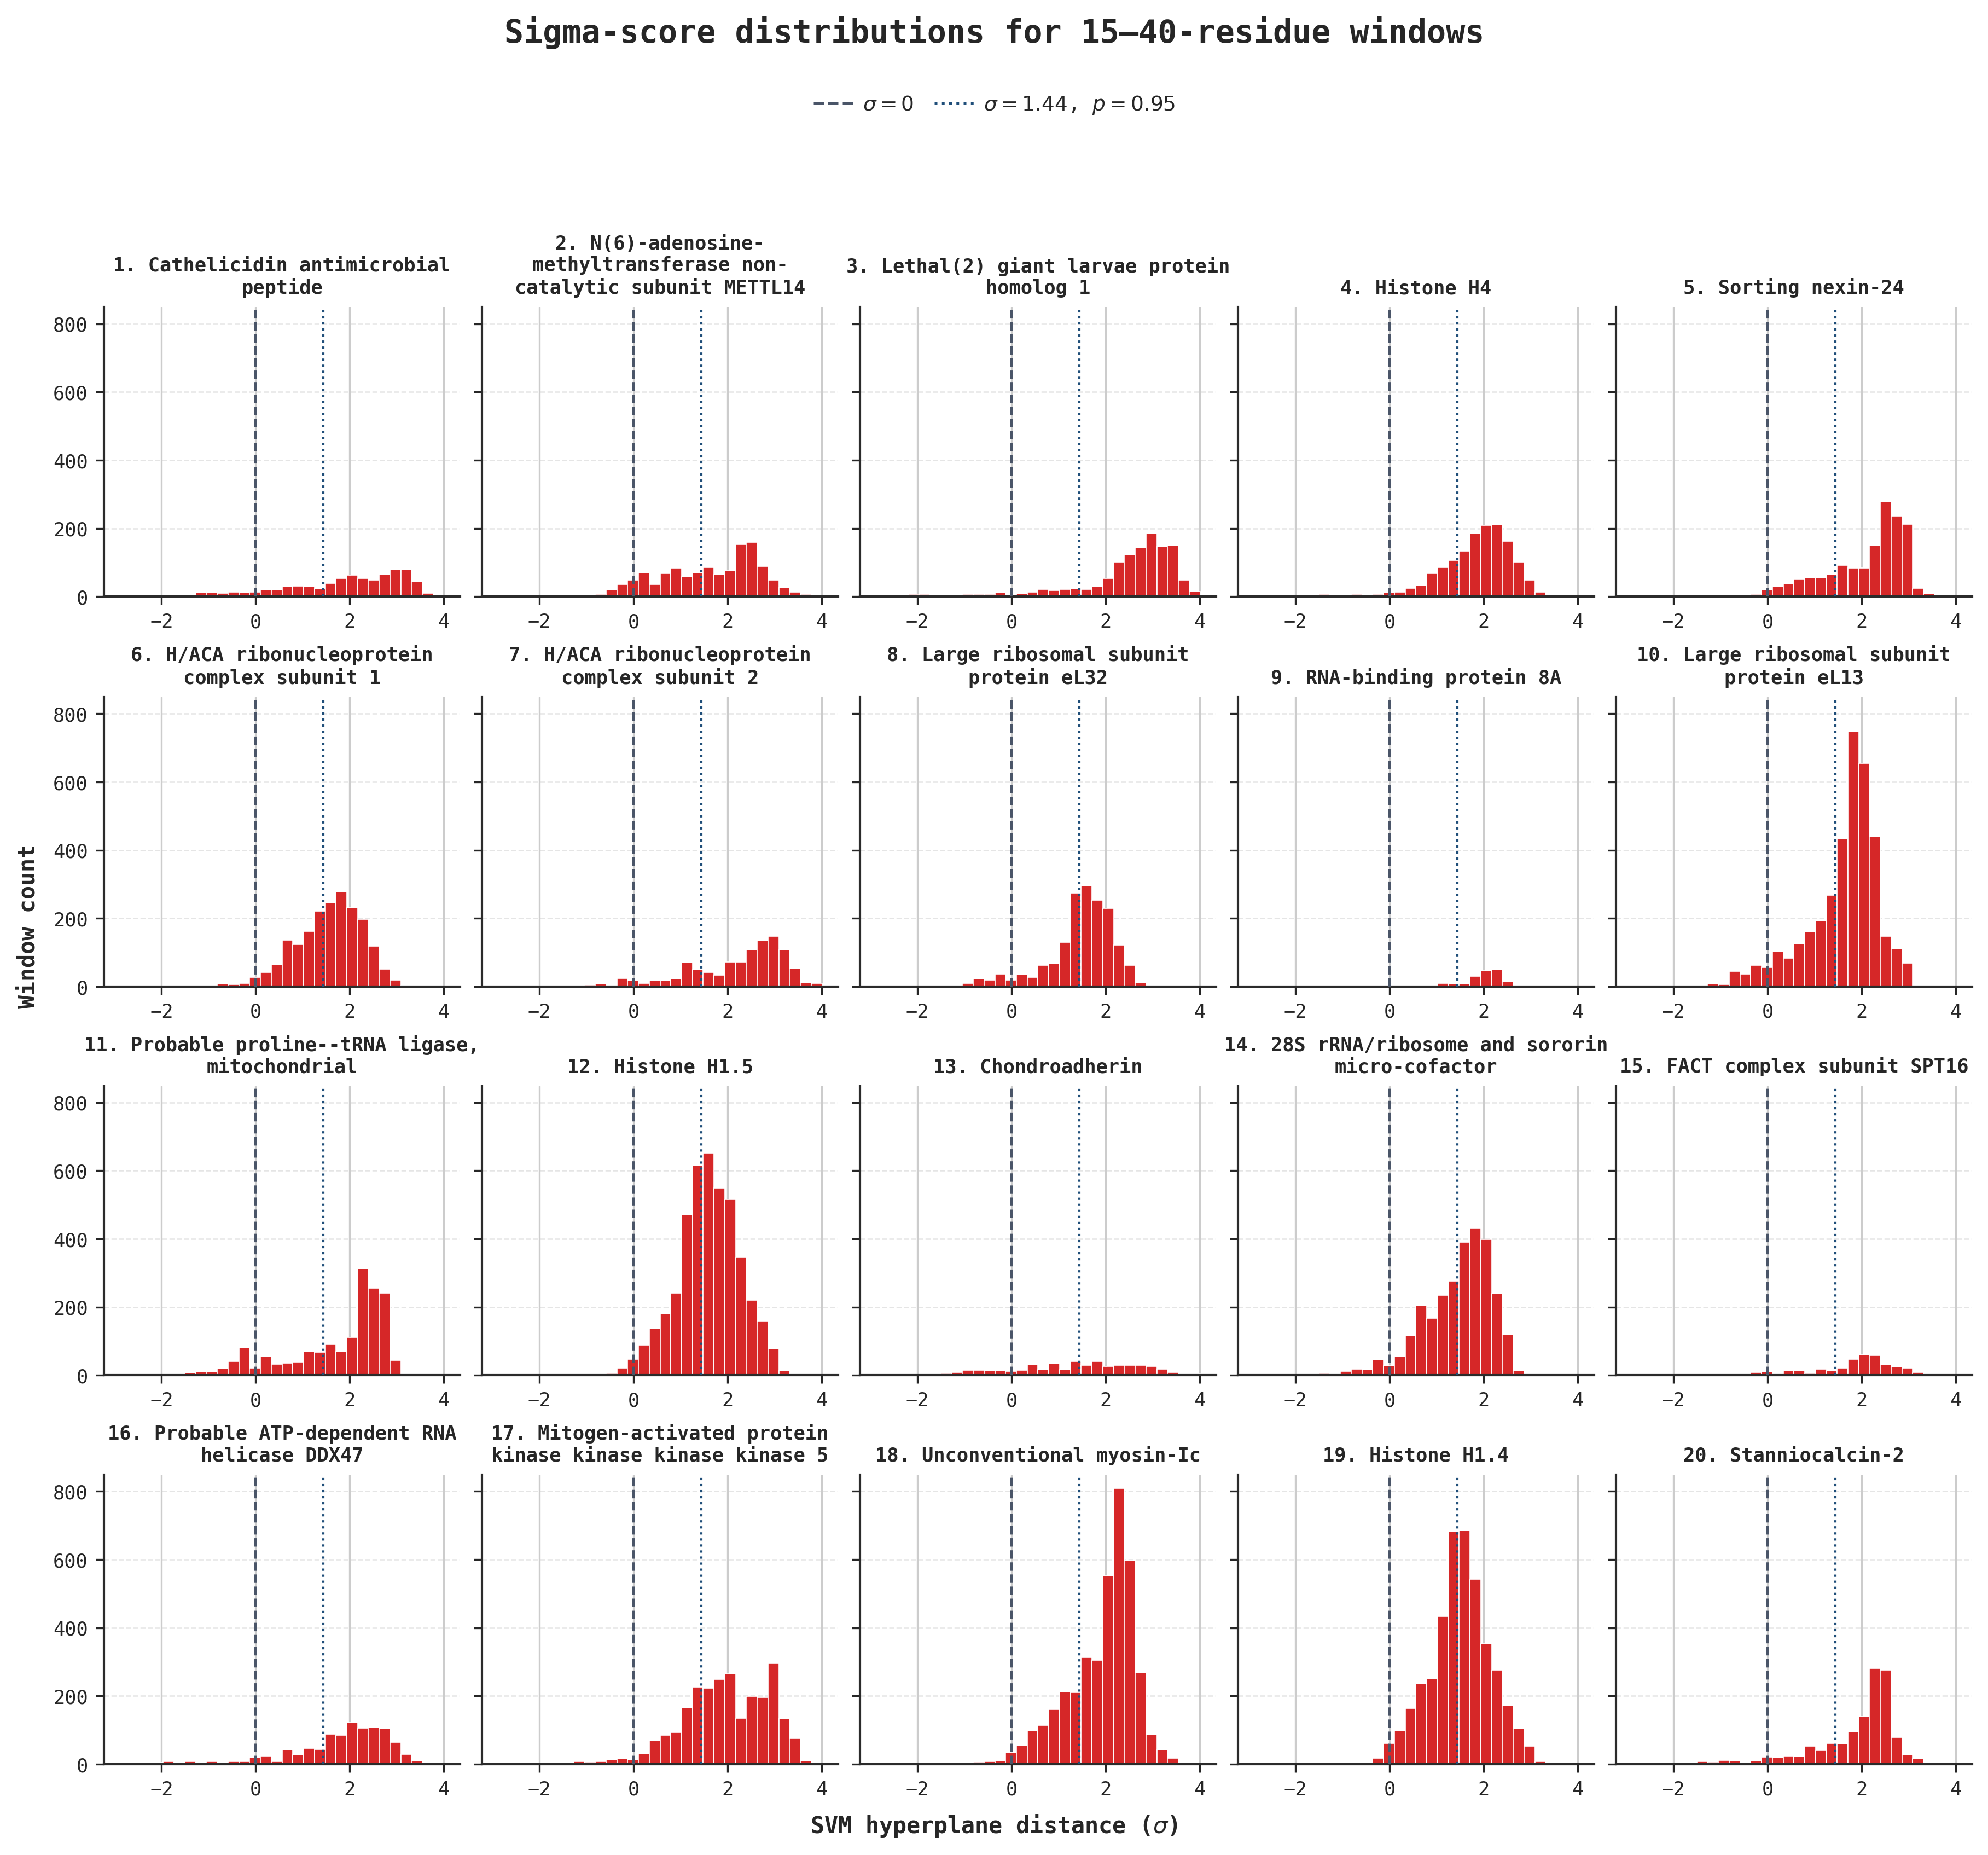

In [4]:
from matplotlib.lines import Line2D

PANEL_COLOR = "#d62728"
SPINE_COLOR = "#2b2b2b"
ZERO_LINE_COLOR = "#4A5568"
P95_LINE_COLOR = "#1f4e79"
TARGET_P_AMP = 0.95
X_AXIS_LABEL = r"SVM hyperplane distance ($\sigma$)"
Y_AXIS_LABEL = "Window count"


def fragment_label(rank: int, name: str) -> str:
    return f"{rank}. " + "\n".join(textwrap.wrap(name, width=30))


def style_distribution_axis(axis: plt.Axes) -> None:
    axis.set_axisbelow(True)
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.spines["left"].set_color(SPINE_COLOR)
    axis.spines["bottom"].set_color(SPINE_COLOR)
    axis.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    axis.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8)
    axis.tick_params(axis="x", labelbottom=True)


def sigma_for_probability(
    sigma: np.ndarray,
    p_amp: np.ndarray,
    target: float = TARGET_P_AMP,
) -> float:
    """Invert sklearn-style Platt scaling P = 1 / (1 + exp(A σ + B))."""
    from scipy.optimize import curve_fit

    sigma = np.asarray(sigma, dtype=float)
    p_amp = np.asarray(p_amp, dtype=float)
    mask = np.isfinite(sigma) & np.isfinite(p_amp)
    sigma = sigma[mask]
    p_amp = np.clip(p_amp[mask], 1e-6, 1 - 1e-6)
    if sigma.size < 2:
        raise ValueError("Need at least two finite sigma/p_amp pairs to invert Platt scaling.")

    def platt(values: np.ndarray, platt_a: float, platt_b: float) -> np.ndarray:
        return 1.0 / (1.0 + np.exp(platt_a * values + platt_b))

    (platt_a, platt_b), _ = curve_fit(platt, sigma, p_amp, p0=(-1.0, 0.0), maxfev=20000)
    if abs(platt_a) < 1e-12:
        raise ValueError("Platt slope is degenerate; cannot solve for sigma.")
    return float((np.log((1.0 - target) / target) - platt_b) / platt_a)


def draw_reference_sigma_lines(axis: plt.Axes, sigma_at_p95: float) -> None:
    axis.axvline(0, color=ZERO_LINE_COLOR, linewidth=1.0, linestyle="--", zorder=3)
    axis.axvline(sigma_at_p95, color=P95_LINE_COLOR, linewidth=1.0, linestyle=":", zorder=3)


def reference_sigma_legend_handles(sigma_at_p95: float) -> list[Line2D]:
    return [
        Line2D(
            [0],
            [0],
            color=ZERO_LINE_COLOR,
            linestyle="--",
            linewidth=1.2,
            label=r"$\sigma = 0$",
        ),
        Line2D(
            [0],
            [0],
            color=P95_LINE_COLOR,
            linestyle=":",
            linewidth=1.2,
            label=rf"$\sigma = {sigma_at_p95:.2f}$, $p = {TARGET_P_AMP:.2f}$",
        ),
    ]


def decorate_distribution_figure(
    figure: plt.Figure,
    sigma_at_p95: float,
    title: str,
    subtitle: str | None = None,
) -> None:
    figure.supxlabel(X_AXIS_LABEL, fontsize=10, fontweight="bold")
    figure.supylabel(Y_AXIS_LABEL, fontsize=10, fontweight="bold")

    # Reserve a top band so title, subtitle, and line legend can stack
    # without competing with constrained_layout's outside-legend slot.
    header_top = 0.84 if subtitle else 0.88
    layout_engine = figure.get_layout_engine()
    if layout_engine is not None:
        # Leave enough top band for title / subtitle / line legend.
        layout_engine.set(rect=(0.0, 0.0, 1.0, header_top))

    figure.text(
        0.5,
        0.995,
        title,
        transform=figure.transFigure,
        ha="center",
        va="top",
        fontsize=14,
        fontweight="bold",
        fontfamily="monospace",
    )
    if subtitle:
        subtitle_y = 0.940
        # Approximate bottom of the subtitle text band.
        subtitle_bottom = subtitle_y - 0.025
        figure.text(
            0.5,
            subtitle_y,
            subtitle,
            transform=figure.transFigure,
            ha="center",
            va="top",
            fontsize=11,
            fontweight="normal",
            fontfamily="monospace",
        )
        # Center the line legend in the gap between subtitle and plots.
        legend_y = 0.5 * (subtitle_bottom + header_top)
        legend_loc = "center"
    else:
        legend_y = 0.955
        legend_loc = "upper center"

    figure.legend(
        handles=reference_sigma_legend_handles(sigma_at_p95),
        loc=legend_loc,
        bbox_to_anchor=(0.5, legend_y),
        bbox_transform=figure.transFigure,
        ncol=2,
        fontsize=9,
        frameon=False,
        borderaxespad=0.0,
        borderpad=0.2,
        labelspacing=0.2,
        handletextpad=0.4,
        columnspacing=1.0,
    )


fragment_count = len(fragment_order)
column_count = 5
row_count = int(np.ceil(fragment_count / column_count))
figure, axes = plt.subplots(
    row_count,
    column_count,
    figsize=(12, 2.8 * row_count),
    dpi=300,
    sharex=True,
    sharey=True,
    constrained_layout=True,
)
finite_sigma = window_predictions["sigma"].dropna().to_numpy(dtype=float)
bin_edges = np.linspace(finite_sigma.min(), finite_sigma.max(), 31)
sigma_at_p95 = sigma_for_probability(
    window_predictions["sigma"].to_numpy(dtype=float),
    window_predictions["p_amp"].to_numpy(dtype=float),
    TARGET_P_AMP,
)
print(f"Sigma equivalent to p = {TARGET_P_AMP:.2f}: {sigma_at_p95:.4f}")

for fragment_id, axis in zip(fragment_order, axes.flat, strict=False):
    group = window_predictions.loc[window_predictions["fragment_id"] == fragment_id]
    scores = group["sigma"].dropna().to_numpy(dtype=float)
    rank = fragment_rank[fragment_id]
    name = str(group["parent_name"].iloc[0])
    style_distribution_axis(axis)
    axis.hist(
        scores,
        bins=bin_edges,
        color=PANEL_COLOR,
        edgecolor="white",
        linewidth=0.4,
        zorder=2,
    )
    draw_reference_sigma_lines(axis, sigma_at_p95)
    axis.set_title(fragment_label(rank, name), fontsize=8.5, fontweight="bold", pad=6)

for axis in axes.flat[fragment_count:]:
    axis.set_visible(False)

decorate_distribution_figure(
    figure,
    sigma_at_p95,
    "Sigma-score distributions for 15–40-residue windows",
)
plt.show()

## Highest-sigma fragment window per top cluster

For each of the top 10 clusters, select the window with the highest SVM sigma score. Name and DNGC describe that window's parent sequence.

In [5]:
TOP_CLUSTER_ORDER = [30, 106, 44, 22, 43, 65, 8, 27, 15, 12]
CLUSTER_DATA_DIR = ROOT / "data" / "skin_samples" / "top_fragments" / "top_10_clusters"
CLUSTER_FRAGMENTS_CSV = CLUSTER_DATA_DIR / "fragment_sequences_with_flanks.csv"
CLUSTER_WINDOW_PREDICTIONS_CSV = latest_raw_predictions(CLUSTER_DATA_DIR / "results")

cluster_fragments = pd.read_csv(CLUSTER_FRAGMENTS_CSV)
cluster_raw_predictions = pd.read_csv(CLUSTER_WINDOW_PREDICTIONS_CSV)
cluster_window_predictions = attach_fragment_metadata(
    cluster_fragments,
    cluster_raw_predictions,
)
cluster_window_predictions["window_length"] = (
    cluster_window_predictions["window_end_0based_exclusive"]
    - cluster_window_predictions["window_start_0based"]
)

cluster_order = {cluster: rank for rank, cluster in enumerate(TOP_CLUSTER_ORDER)}
cluster_top_windows = (
    cluster_window_predictions.sort_values("sigma", ascending=False, kind="mergesort")
    .drop_duplicates("cluster")
    .assign(_cluster_order=lambda frame: frame["cluster"].map(cluster_order))
    .sort_values("_cluster_order", kind="mergesort")
)
if set(cluster_top_windows["cluster"]) != set(TOP_CLUSTER_ORDER):
    raise ValueError("Window results do not contain the expected top 10 clusters.")

cluster_window_table = cluster_top_windows[
    ["cluster", "parent_name", "DNGC", "window_sequence", "window_length", "sigma"]
].rename(
    columns={
        "parent_name": "name",
        "window_sequence": "fragment sequence",
        "window_length": "top fragment length",
        "sigma": "top fragment sigma",
    }
)
cluster_window_table["cluster"] = cluster_window_table["cluster"].map(
    lambda value: f"Cluster {int(value)}"
)
cluster_window_table = cluster_window_table.reset_index(drop=True)

display(
    cluster_window_table.style.hide(axis="index").format(
        {"DNGC": "{:.4f}", "top fragment sigma": "{:.4f}"}
    )
)

cluster,name,DNGC,fragment sequence,top fragment length,top fragment sigma
Cluster 30,Cathelicidin antimicrobial peptide,1.5798,FKRIVQRIKDFLRNLVPR,18,3.6964
Cluster 106,Histone H1.1,1.0057,KPLAGKKAKKPAKAAAASKKKP,22,2.2368
Cluster 44,Endoplasmin,0.8447,HKLLKVIRKKLVRKTLDMIKKI,22,2.9137
Cluster 22,Probable ATP-dependent RNA helicase DDX47,1.1410,KKVQKLQRAALKNPVKCAVSSKYQTV,26,3.5117
Cluster 43,Zinc finger protein 518A,0.5845,KRHKTFKPVSSVKERFVLKLTLKKTSKNN,29,2.2904
Cluster 65,LLGL scribble cell polarity complex component 2,0.7773,SRVKSLKKSLRQSFRR,16,3.8862
Cluster 8,Protein disulfide-isomerase A6,0.6728,LRQLVKDRLGGRSGGYSSGKQGR,23,3.0975
Cluster 27,Protein DEK,0.5310,KPSGKPLPKSKKTCSKGSKK,20,3.4733
Cluster 15,Translationally-controlled tumor protein,0.4243,KKYIKDYMKSIKGKL,15,3.4299
Cluster 12,Serine/threonine-protein phosphatase 2A 56 kDa regulatory subunit epsilon isoform,0.4751,LKTVLHRIYGKFLGLRAFIRK,21,3.2511


In [6]:
cluster_window_positions = top_window_original_positions(cluster_top_windows, cluster_fragments)
display(cluster_window_positions.style.hide(axis="index"))

fragment_id,position
sp|P49913|CAMP_HUMAN-135,18 (150–167)
sp|Q02539|H11_HUMAN-14,22 (17–38)
sp|P14625|ENPL_HUMAN-454,22 (454–475)
sp|Q9H0S4|DDX47_HUMAN-206,26 (210–235)
sp|Q6AHZ1|Z518A_HUMAN-1404,29 (1405–1433)
sp|Q6P1M3|L2GL2_HUMAN-633,16 (641–656)
sp|Q15084|PDIA6_HUMAN-129,23 (131–153)
sp|P35659|DEK_HUMAN-180,20 (187–206)
sp|P13693|TCTP_HUMAN-88,15 (89–103)
sp|Q16537|2A5E_HUMAN-201,21 (199–219)


## Top candidate profile and window context

Verify the top candidate comes from cluster 30, then show the positive portion of its mean σNGC profile on the complete parent-sequence axis. The bordered upper row displays the full parent sequence and labels the final 37 residues as LL37. Separate colors mark the 10-residue prediction buffer, candidate fragment, and highest-σ window.

Verified top candidate: cluster 30, sp|P49913|CAMP_HUMAN-135


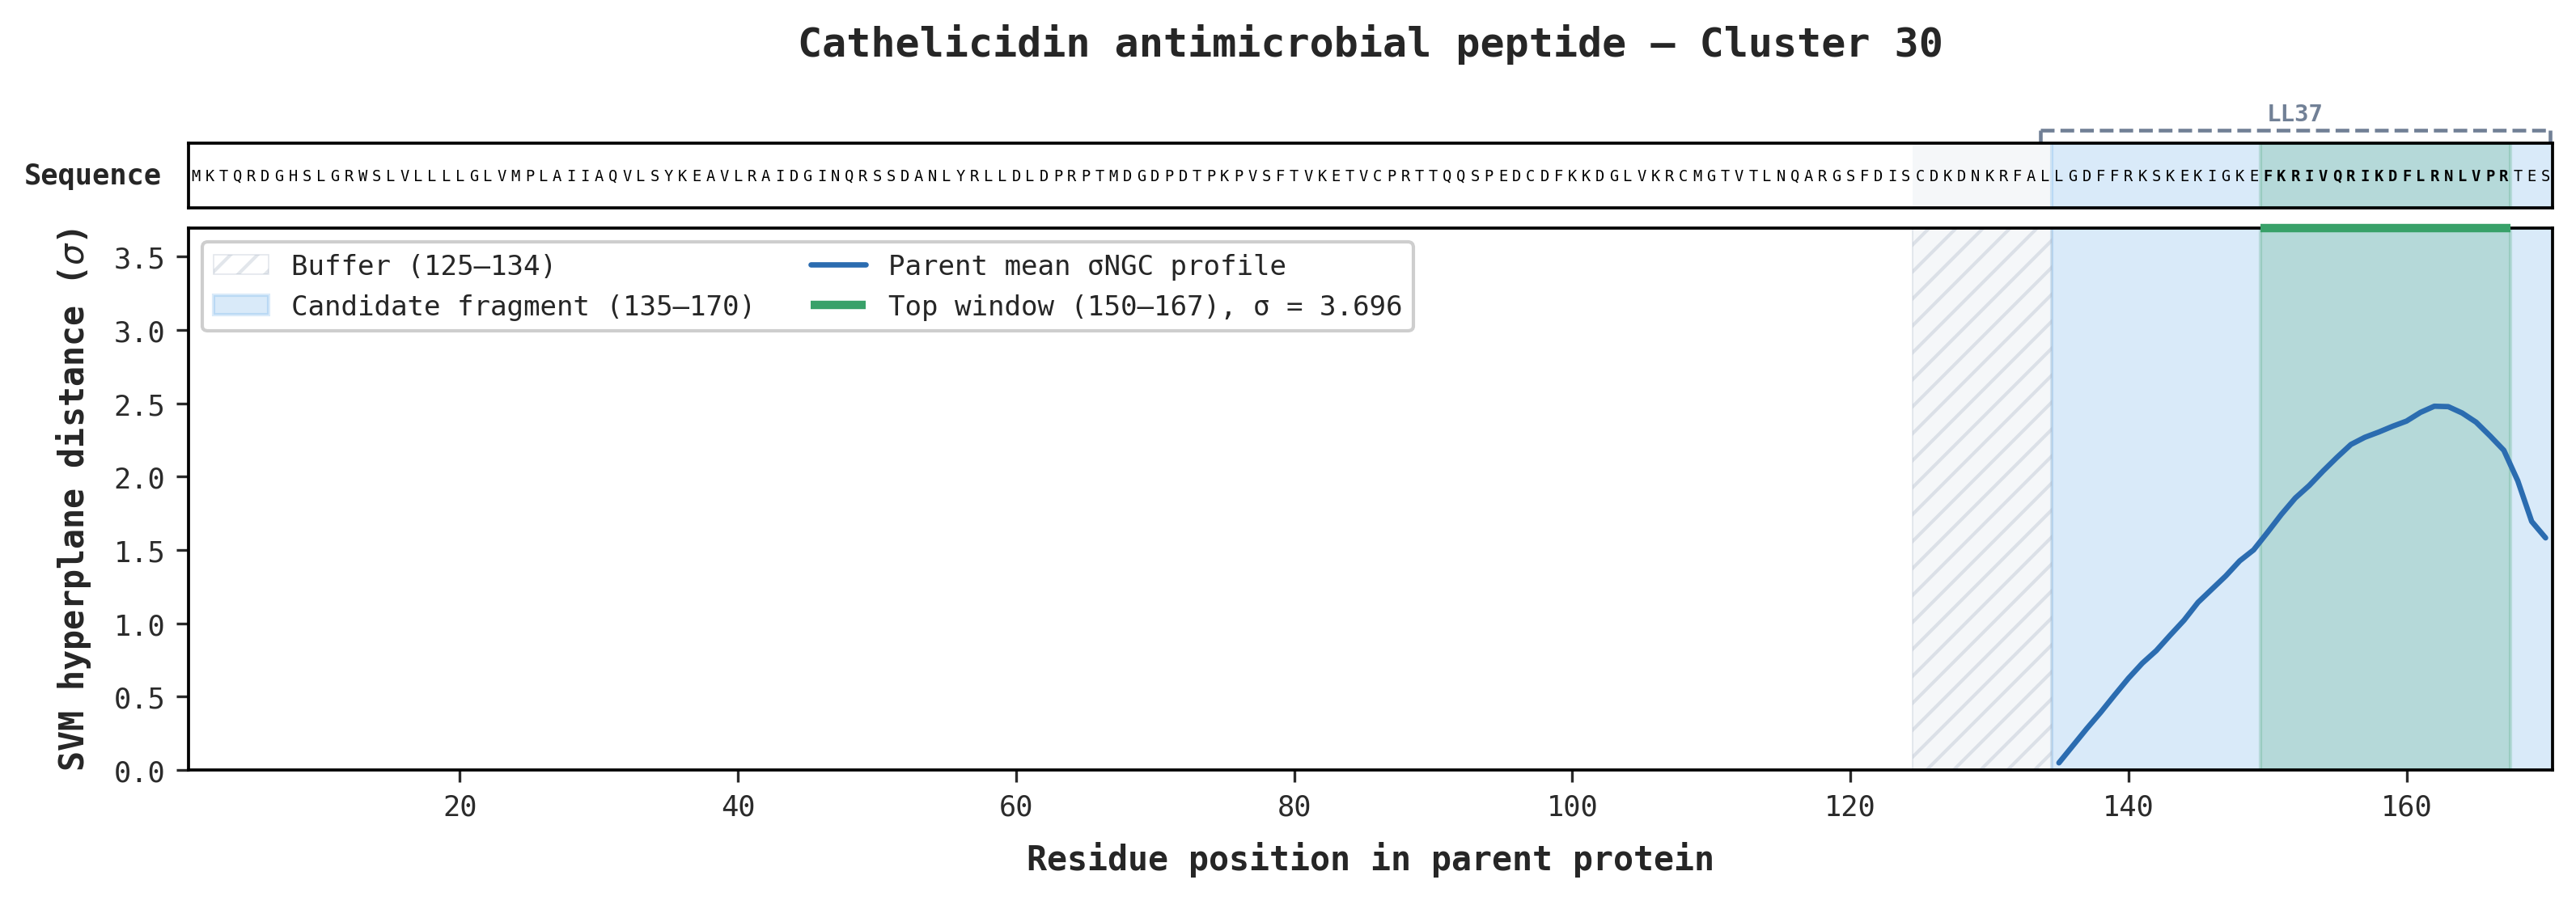

In [7]:
CANDIDATE_CLUSTER = 30
CANDIDATE_PROFILE_COLOR = "#2B6CB0"
BUFFER_COLOR = "#CBD5E1"
BUFFER_HATCH_COLOR = "#A0AEC0"
FRAGMENT_COLOR = "#4299E1"
TOP_WINDOW_COLOR = "#38A169"
LL37_COLOR = "#718096"
LL37_LENGTH = 37


def latest_profile_csv(data_dir: Path) -> Path:
    filename = "window_sequence_profiles.csv"
    candidates = list((data_dir / "results" / "runs").glob(f"*/{filename}"))
    if candidates:
        return max(candidates, key=lambda path: path.stat().st_mtime_ns)
    legacy = data_dir / "results" / filename
    if legacy.is_file():
        return legacy
    raise FileNotFoundError(f"Could not find {filename} under {data_dir / 'results'}")


def sequence_span_on_parent(fragment: pd.Series) -> tuple[int, int]:
    fragment_start, fragment_end = parse_fragment_position(fragment["position"])
    sequence_length = len(str(fragment["sequence"]))
    sequence_type = str(fragment["sequence_type"])
    if sequence_type == "before_sequence":
        return fragment_end - sequence_length + 1, fragment_end
    if sequence_type == "existing_sequence":
        return fragment_start, fragment_end
    if sequence_type == "after_sequence":
        return fragment_start, fragment_start + sequence_length - 1
    raise ValueError(f"Unrecognized sequence_type: {sequence_type!r}")


def load_parent_sigma_profile(parent_id: str) -> tuple[np.ndarray, str]:
    path = latest_profile_csv(ROOT / "data" / "skin_samples")
    frame = pd.read_csv(path)
    rows = frame.loc[frame["id"].astype(str) == str(parent_id)]
    if len(rows) != 1:
        raise ValueError(f"Expected one profile for {parent_id}, found {len(rows)}.")
    row = rows.iloc[0]
    delimiter = str(row.get("profile_delimiter", ";") or ";")
    sigma = np.fromstring(str(row["hyperplane_distance_mean_profile"]), sep=delimiter)
    expected_length = int(row["sequence_length"])
    if sigma.size != expected_length:
        raise ValueError(f"Profile length {sigma.size} does not match {expected_length}.")
    return sigma, str(row.get("name", parent_id))


def load_parent_sequence(parent_id: str) -> str:
    fasta_path = ROOT / "data" / "skin_samples" / "idmapping_2026_08_06.fasta"
    sequence: list[str] = []
    collecting = False
    with fasta_path.open() as handle:
        for line in handle:
            if line.startswith(">"):
                if collecting:
                    break
                collecting = line[1:].split(maxsplit=1)[0] == parent_id
            elif collecting:
                sequence.append(line.strip())
    if not sequence:
        raise ValueError(f"Could not find {parent_id} in {fasta_path}.")
    return "".join(sequence)


def verified_cluster_candidate(cluster_id: int) -> tuple[pd.Series, pd.Series]:
    if not TOP_CLUSTER_ORDER or int(TOP_CLUSTER_ORDER[0]) != cluster_id:
        raise ValueError(f"Expected cluster {cluster_id} to rank first by weighted DNGC.")
    matches = cluster_top_windows.loc[cluster_top_windows["cluster"].astype(int) == cluster_id]
    if len(matches) != 1:
        raise ValueError(f"Expected one top window for cluster {cluster_id}, found {len(matches)}.")
    candidate = matches.iloc[0]
    source = cluster_fragments.iloc[int(candidate["source_row"])]
    if str(source["id"]) != str(candidate["fragment_id"]):
        raise ValueError("Candidate window and SVM input sequence do not match.")
    return candidate, source


def candidate_spans(candidate: pd.Series, svm_input: pd.Series) -> dict[str, tuple[int, int]]:
    input_start, input_end = sequence_span_on_parent(svm_input)
    fragment_start, fragment_end = parse_fragment_position(svm_input["position"])
    top_start = input_start + int(candidate["window_start_0based"])
    top_end = input_start + int(candidate["window_end_0based_exclusive"]) - 1
    sequence = str(svm_input["sequence"])
    top_sequence = str(candidate["window_sequence"])
    offset = top_start - input_start
    if sequence[offset : offset + len(top_sequence)] != top_sequence:
        raise ValueError("Top-window sequence does not match the selected SVM input.")
    return {
        "input": (input_start, input_end),
        "fragment": (fragment_start, fragment_end),
        "top": (top_start, top_end),
    }


def style_candidate_axis(axis: plt.Axes) -> None:
    axis.set_axisbelow(True)
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(0.9)
    axis.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


def buffer_spans(spans: dict[str, tuple[int, int]]) -> list[tuple[int, int]]:
    input_start, input_end = spans["input"]
    fragment_start, fragment_end = spans["fragment"]
    buffers = []
    if input_start < fragment_start:
        buffers.append((input_start, fragment_start - 1))
    if fragment_end < input_end:
        buffers.append((fragment_end + 1, input_end))
    return buffers


def add_candidate_spans(
    axis: plt.Axes,
    spans: dict[str, tuple[int, int]],
    *,
    labels: bool,
    hatch_buffer: bool,
) -> None:
    fragment_start, fragment_end = spans["fragment"]
    top_start, top_end = spans["top"]
    buffers = buffer_spans(spans)
    for index, (buffer_start, buffer_end) in enumerate(buffers):
        buffer_label = f"Buffer ({buffer_start}–{buffer_end})" if labels and index == 0 else None
        axis.axvspan(
            buffer_start - 0.5,
            buffer_end + 0.5,
            facecolor=BUFFER_COLOR,
            edgecolor="none",
            alpha=0.18,
            label=buffer_label if not hatch_buffer else None,
            zorder=1,
        )
        if hatch_buffer:
            axis.axvspan(
                buffer_start - 0.5,
                buffer_end + 0.5,
                facecolor="none",
                edgecolor=BUFFER_HATCH_COLOR,
                hatch="///",
                linewidth=0.4,
                alpha=0.30,
                label=buffer_label,
                zorder=2,
            )
    axis.axvspan(
        fragment_start - 0.5,
        fragment_end + 0.5,
        color=FRAGMENT_COLOR,
        alpha=0.20,
        label=f"Candidate fragment ({fragment_start}–{fragment_end})" if labels else None,
        zorder=1,
    )
    axis.axvspan(
        top_start - 0.5,
        top_end + 0.5,
        color=TOP_WINDOW_COLOR,
        alpha=0.22,
        zorder=2,
    )


def draw_residue_row(
    axis: plt.Axes,
    sequence: str,
    spans: dict[str, tuple[int, int]],
) -> None:
    add_candidate_spans(axis, spans, labels=False, hatch_buffer=False)
    fragment_start, fragment_end = spans["fragment"]
    top_start, top_end = spans["top"]
    buffers = buffer_spans(spans)
    for position, residue in enumerate(sequence, start=1):
        is_top = top_start <= position <= top_end
        axis.text(
            position,
            0.5,
            residue,
            ha="center",
            va="center",
            fontsize=4.5,
            fontweight="bold" if is_top else "normal",
            color="black",
        )

    ll37_start = len(sequence) - LL37_LENGTH + 1
    ll37_end = len(sequence)
    bracket_transform = axis.get_xaxis_transform()
    axis.plot(
        [ll37_start - 0.35, ll37_end + 0.35],
        [1.20, 1.20],
        transform=bracket_transform,
        color=LL37_COLOR,
        linestyle="--",
        linewidth=1.1,
        clip_on=False,
    )
    axis.plot(
        [ll37_start - 0.35, ll37_start - 0.35],
        [1.00, 1.20],
        transform=bracket_transform,
        color=LL37_COLOR,
        linestyle="--",
        linewidth=1.1,
        clip_on=False,
    )
    axis.plot(
        [ll37_end + 0.35, ll37_end + 0.35],
        [1.00, 1.20],
        transform=bracket_transform,
        color=LL37_COLOR,
        linestyle="--",
        linewidth=1.1,
        clip_on=False,
    )
    axis.text(
        (ll37_start + ll37_end) / 2,
        1.28,
        "LL37",
        transform=bracket_transform,
        ha="center",
        va="bottom",
        fontsize=7.0,
        fontweight="bold",
        color=LL37_COLOR,
        clip_on=False,
    )
    axis.set_xlim(0.5, len(sequence) + 0.5)
    axis.set_ylim(0.0, 1.0)
    axis.set_yticks([])
    axis.set_ylabel("Sequence", fontsize=8.5, fontweight="bold", rotation=0, ha="right", va="center", labelpad=8)
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(0.9)
    axis.tick_params(axis="x", bottom=False, labelbottom=False)


def plot_top_candidate_profile(candidate: pd.Series, svm_input: pd.Series) -> None:
    parent_id = str(candidate["parent_id"])
    sigma_profile, parent_name = load_parent_sigma_profile(parent_id)
    parent_sequence = load_parent_sequence(parent_id)
    if len(parent_sequence) != sigma_profile.size:
        raise ValueError("Parent sequence and sigma profile lengths do not match.")

    spans = candidate_spans(candidate, svm_input)
    top_start, top_end = spans["top"]
    positions = np.arange(1, sigma_profile.size + 1)
    positive_mask = np.isfinite(sigma_profile) & (sigma_profile > 0.0)
    positive_profile = np.where(positive_mask, sigma_profile, np.nan)

    figure, (sequence_axis, profile_axis) = plt.subplots(
        2,
        1,
        figsize=(10.5, 3.6),
        dpi=300,
        sharex=True,
        gridspec_kw={"height_ratios": [0.38, 3.2], "hspace": 0.02},
        layout="constrained",
    )
    draw_residue_row(sequence_axis, parent_sequence, spans)
    sequence_axis.set_title(
        f"{parent_name} — Cluster {int(candidate['cluster'])}",
        fontsize=12,
        fontweight="bold",
        pad=26,
    )

    style_candidate_axis(profile_axis)
    add_candidate_spans(profile_axis, spans, labels=True, hatch_buffer=True)
    profile_axis.plot(
        positions,
        positive_profile,
        color=CANDIDATE_PROFILE_COLOR,
        linewidth=1.6,
        label="Parent mean σNGC profile",
        zorder=4,
    )
    profile_axis.hlines(
        float(candidate["sigma"]),
        top_start - 0.5,
        top_end + 0.5,
        color=TOP_WINDOW_COLOR,
        linewidth=2.5,
        label=f"Top window ({top_start}–{top_end}), σ = {float(candidate['sigma']):.3f}",
        zorder=6,
        clip_on=False,
    )
    profile_axis.axhline(0.0, color=ZERO_LINE_COLOR, linewidth=0.8, zorder=1)
    profile_axis.set_xlim(0.5, sigma_profile.size + 0.5)
    y_max = float(candidate["sigma"])
    if float(np.nanmax(positive_profile)) > y_max:
        raise ValueError("Parent profile exceeds the selected top-window sigma.")
    profile_axis.set_ylim(0.0, y_max)
    profile_axis.xaxis.set_major_locator(plt.MaxNLocator(integer=True, nbins=9))
    profile_axis.set_xlabel("Residue position in parent protein", fontsize=10, fontweight="bold", labelpad=6)
    profile_axis.set_ylabel(r"SVM hyperplane distance ($\sigma$)", fontsize=10, fontweight="bold", labelpad=6)
    profile_axis.legend(loc="upper left", fontsize=8.2, frameon=True, framealpha=0.95, ncol=2)
    plt.show()


cluster30_candidate, cluster30_svm_input = verified_cluster_candidate(CANDIDATE_CLUSTER)
print(
    f"Verified top candidate: cluster {int(cluster30_candidate['cluster'])}, "
    f"{cluster30_candidate['fragment_id']}"
)
plot_top_candidate_profile(cluster30_candidate, cluster30_svm_input)

## Sigma-score distributions by cluster

For each top cluster, plot the 15–40-residue window sigma distributions. Curves from different fragment sequences within the cluster use different colors.

Cluster sigma equivalent to p = 0.95: 1.4406


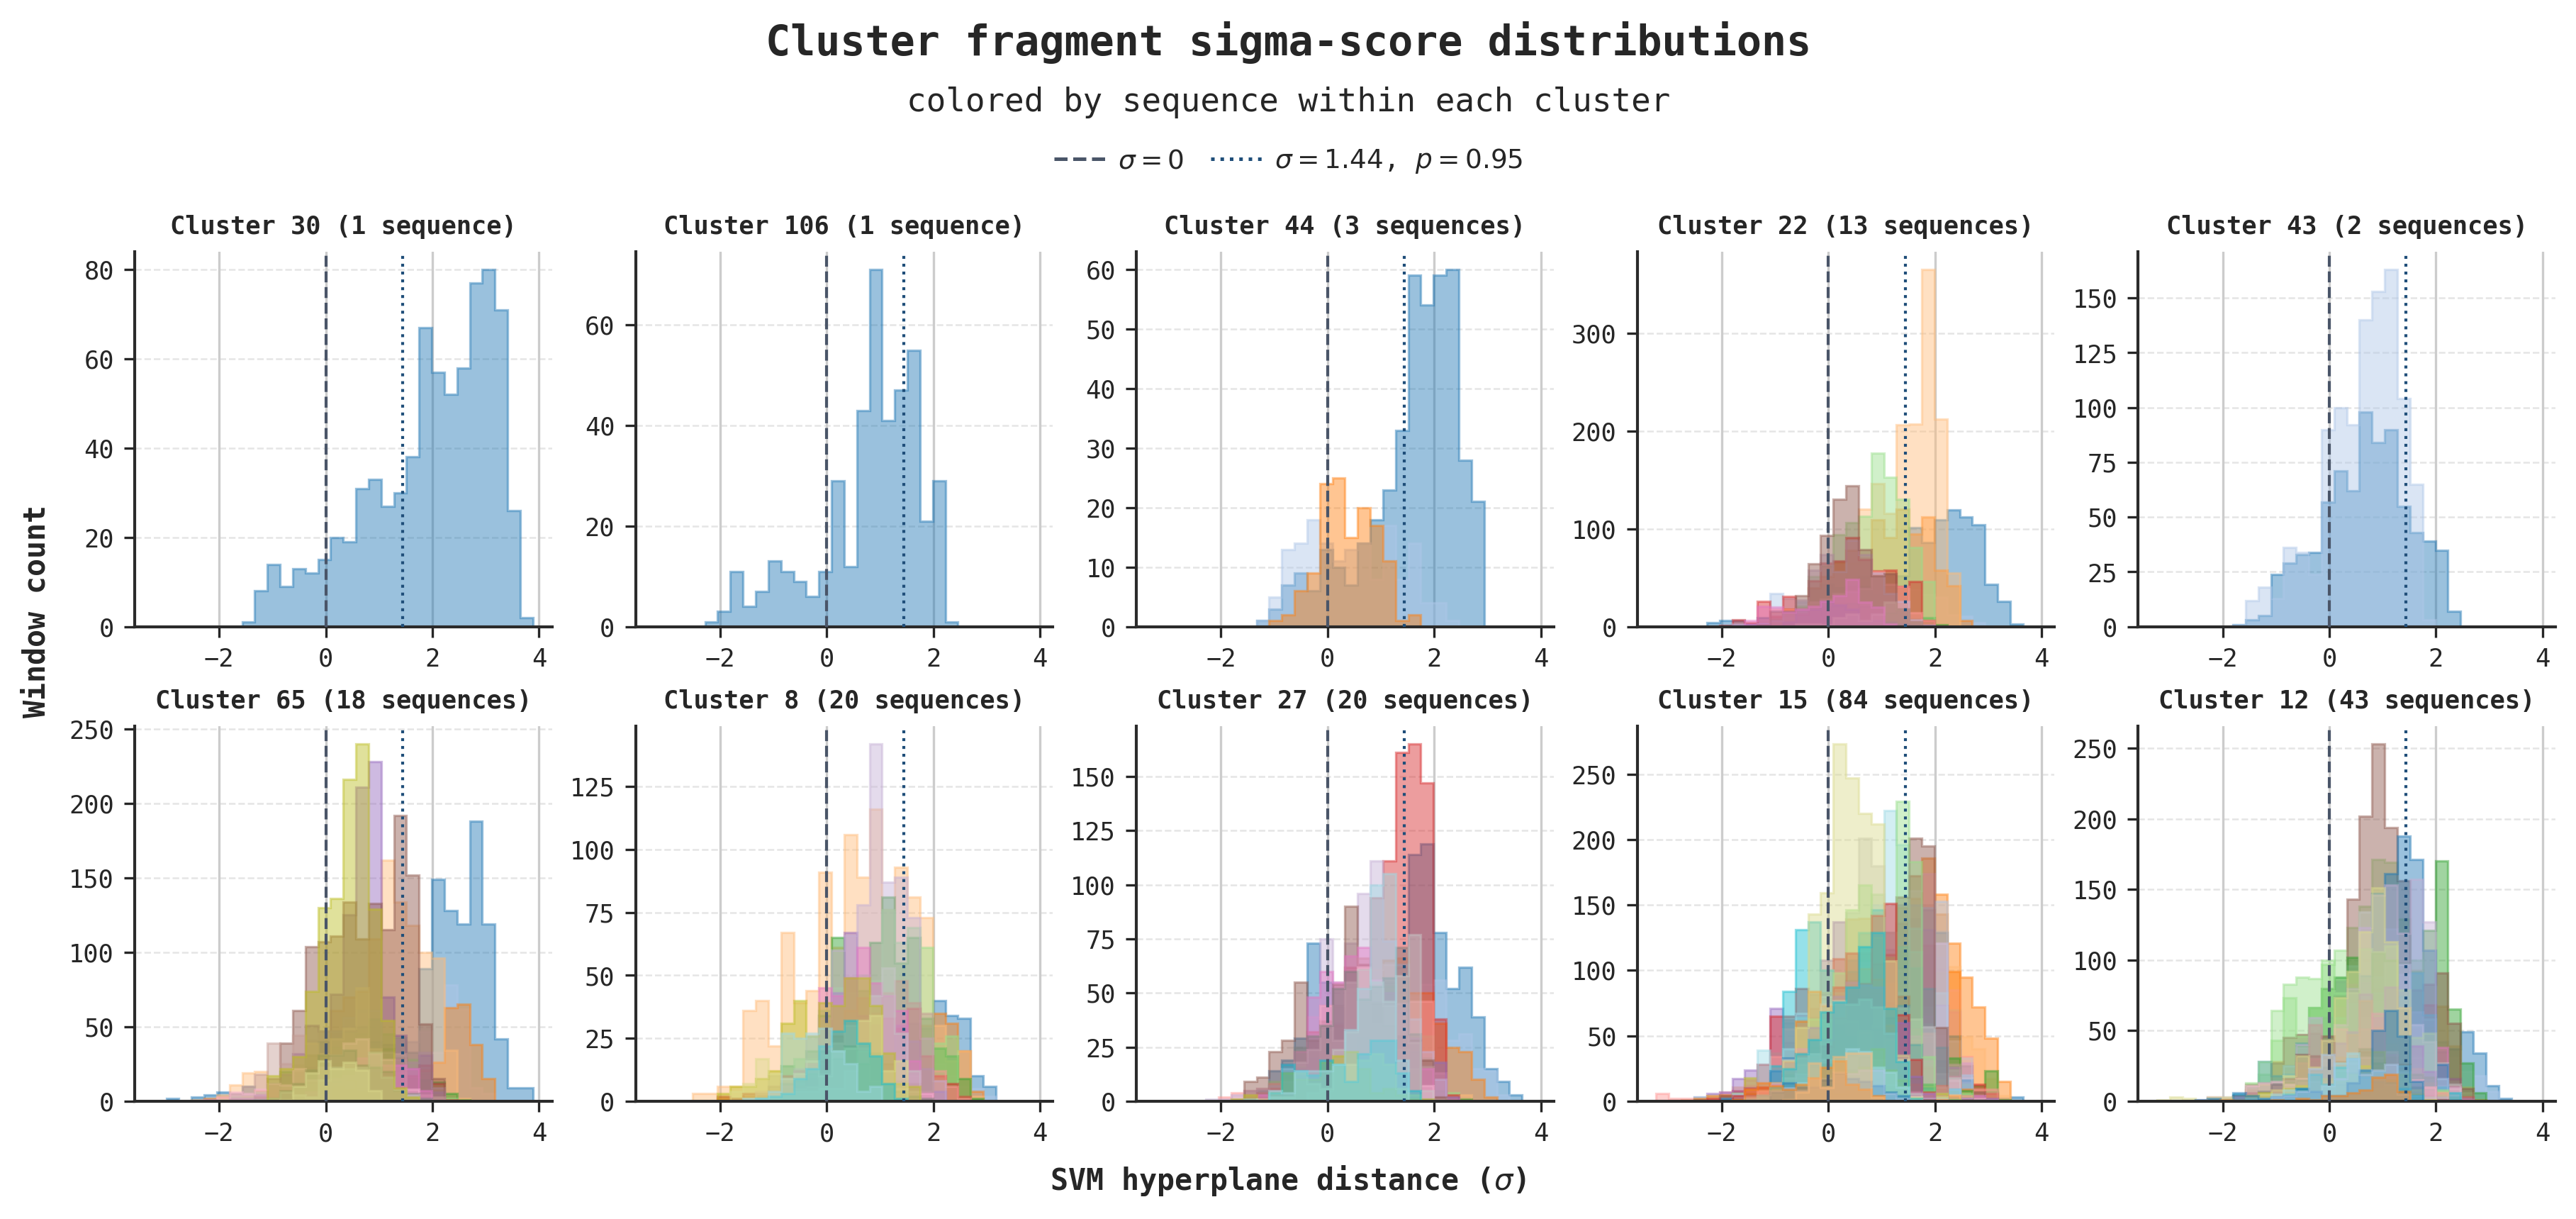

In [8]:
cluster_column_count = 5
cluster_row_count = int(np.ceil(len(TOP_CLUSTER_ORDER) / cluster_column_count))
cluster_figure, cluster_axes = plt.subplots(
    cluster_row_count,
    cluster_column_count,
    figsize=(12, 2.8 * cluster_row_count),
    dpi=300,
    sharex=True,
    sharey=False,
    constrained_layout=True,
)

cluster_finite_sigma = cluster_window_predictions["sigma"].dropna().to_numpy(dtype=float)
cluster_bin_edges = np.linspace(cluster_finite_sigma.min(), cluster_finite_sigma.max(), 31)
sequence_colormap = plt.colormaps["tab20"]
cluster_sigma_at_p95 = sigma_for_probability(
    cluster_window_predictions["sigma"].to_numpy(dtype=float),
    cluster_window_predictions["p_amp"].to_numpy(dtype=float),
    TARGET_P_AMP,
)
print(f"Cluster sigma equivalent to p = {TARGET_P_AMP:.2f}: {cluster_sigma_at_p95:.4f}")

for cluster_id, axis in zip(TOP_CLUSTER_ORDER, cluster_axes.flat, strict=False):
    cluster_group = cluster_window_predictions.loc[
        cluster_window_predictions["cluster"] == cluster_id
    ]
    fragment_ids = (
        cluster_group.groupby("fragment_id", sort=False)["sigma"]
        .max()
        .sort_values(ascending=False)
        .index
        .tolist()
    )
    style_distribution_axis(axis)
    for fragment_index, fragment_id in enumerate(fragment_ids):
        scores = (
            cluster_group.loc[cluster_group["fragment_id"] == fragment_id, "sigma"]
            .dropna()
            .to_numpy(dtype=float)
        )
        color = sequence_colormap(fragment_index % sequence_colormap.N)
        axis.hist(
            scores,
            bins=cluster_bin_edges,
            histtype="stepfilled",
            color=color,
            alpha=0.45,
            edgecolor=color,
            linewidth=0.8,
            zorder=2,
        )
    draw_reference_sigma_lines(axis, cluster_sigma_at_p95)
    sequence_count = len(fragment_ids)
    sequence_label = "sequence" if sequence_count == 1 else "sequences"
    axis.set_title(
        f"Cluster {int(cluster_id)} ({sequence_count} {sequence_label})",
        fontsize=8.5,
        fontweight="bold",
        pad=6,
    )

for axis in cluster_axes.flat[len(TOP_CLUSTER_ORDER) :]:
    axis.set_visible(False)

decorate_distribution_figure(
    cluster_figure,
    cluster_sigma_at_p95,
    "Cluster fragment sigma-score distributions",
    subtitle="colored by sequence within each cluster",
)
plt.show()